In [ ]:
# [env] load .env (KEY=VALUE lines) into os.environ -- see .env.sample
# real env vars / Colab / Kaggle secrets take precedence; empty values are ignored
import os, pathlib
for _p in [pathlib.Path(".env"), pathlib.Path("../.env"),
           pathlib.Path("/content/drive/MyDrive/.env"),
           *sorted(pathlib.Path("/kaggle/input").glob("*/.env"))]:
    if _p.is_file():
        for _line in _p.read_text().splitlines():
            _k, _sep, _v = _line.partition("=")
            _k, _v = _k.strip(), _v.strip().strip("\"'")
            if _sep and _k and _v and not _k.startswith("#"):
                os.environ.setdefault(_k, _v)
        print("env loaded from", _p)
        break
else:
    print("no .env found -- copy .env.sample to .env and fill it in")

# Frequency-split fusion: low frequencies from v3, high frequencies from the bridge

**Idea.** v3 (deterministic regressor) wins PSNR/SSIM; the ResShift bridge wins FID/LPIPS. The error budget (Table IV / Fig. 4a)
says v3's error is mostly low-frequency, i.e. its high frequencies carry little of its PSNR. So

`fused_σ = LowPass_σ(v3) + HighPass_σ(bridge sample)`

should keep most of v3's PSNR while borrowing the bridge's texture (better FID). It is compared on the **same images** with
v3, the bridge, and plain pixel blends `(1-λ)·v3 + λ·bridge` (the baseline it has to beat). No training.

**Protocol.** v3 is decoded with **its fine-tuned decoder** (`regressor_v3_final/base_vae_tuned.pth`, audit P0-2); the bridge with `adapted16_final`. Two split options (`PROTOCOL`):
* `"relative"` (default) — the split the paper's evaluation scripts used (no shuffle). **About 95% of these images were seen in
  training** (audit P0-1), so absolute PSNR/FID are optimistic. Because every variant is built from the same two models' outputs
  on the same images, the *comparison* fusion-vs-blend is still informative. All outputs are labelled `CONTAMINATED`.
* `"heldout"` — rebuild the training-time split and gate on v3's logged 17.668 dB. On Kaggle this **fails**: the training scripts
  shuffled in Colab's directory-listing order of the CSV files, which was never saved (tested: 18.330 / 17.995). Only useful on
  the original Colab disk, or after retraining on a saved split.

**Inputs (Kaggle):** `sar-assets-base` and the dataset `shambac/augmented-sentinel-1-2`. GPU: RTX Pro 6000.
**Outputs:** `/kaggle/working/freq_split/` — `results.csv`, `results.json`, `per_image.csv`, `psnr_fid.png`, `grid.png`.

In [1]:
# ===================== KAGGLE SETUP (added for Kaggle) - run this cell first =====================
# Works with Internet OFF (competition GPUs) and ON. Attach as notebook inputs:
#   * the "sar-assets-*" datasets built with 00_build_assets_kaggle.ipynb (model weights, wheels, torch weights)
#   * the data this notebook needs (see the markdown cell above)
import os, sys, glob, shutil, subprocess, importlib.util

OFFLINE = True          # set False when Internet is ON for this session (enables pip / HF downloads / HF pushes)
INPUT = "/kaggle/input"


def _find(pattern, depth=7, max_entries=300):
    # Breadth-first search for <dir>/<pattern> under /kaggle/input (mounts look like
    # /kaggle/input/datasets/<user>/<dataset>/...). Folders with more than `max_entries` children
    # (image folders) are not descended into, so this stays fast next to the 600k-file datasets.
    out, level = [], [INPUT]
    for _ in range(depth):
        nxt = []
        for d in level:
            if os.path.exists(os.path.join(d, pattern)):
                out.append(os.path.join(d, pattern))
                continue
            try:
                kids = []
                with os.scandir(d) as it:
                    for i, e in enumerate(it):
                        if i >= max_entries:
                            kids = []
                            break
                        if e.is_dir():
                            kids.append(e.path)
                nxt += kids
            except OSError:
                pass
        level = nxt
    return sorted(set(out))


# 1) model repos (plain files: repos/<owner>__<name>/...), torch hub weights, pip wheels
REPO_ROOTS = _find("repos")
os.environ["SAR_ASSET_REPOS"] = os.pathsep.join(REPO_ROOTS)
for t in _find("torch"):
    shutil.copytree(t, "/tmp/torch_home", dirs_exist_ok=True)
os.environ["TORCH_HOME"] = "/tmp/torch_home"

NEED = {"lpips": "lpips", "torch_fidelity": "torch-fidelity", "diffusers": "diffusers", "transformers": "transformers",
        "accelerate": "accelerate", "safetensors": "safetensors", "torchmetrics": "torchmetrics",
        "huggingface_hub": "huggingface_hub", "peft": "peft", "kagglehub": "kagglehub"}
import site


def _missing():
    importlib.invalidate_caches()
    for p in (site.getusersitepackages(),):          # pip may fall back to the user site, which is not on sys.path yet
        if os.path.isdir(p) and p not in sys.path:
            sys.path.append(p)
    return [pip for mod, pip in NEED.items() if importlib.util.find_spec(mod) is None]


def _pip(args):
    r = subprocess.run([sys.executable, "-m", "pip", "install", *args], capture_output=True, text=True)
    if r.returncode != 0:
        print("pip failed:\n", (r.stdout + r.stderr)[-1500:])


missing = _missing()
WHEELS = _find("wheels")
print("packages missing at start:", missing or "none", "| wheels folders:", WHEELS or "none found")
if missing and WHEELS:
    _pip(["-q", "--no-index", "--no-deps", *sum([["--find-links", w] for w in WHEELS], []), *missing])
    missing = _missing()
if missing and not OFFLINE:
    _pip(["-q", *missing])
    missing = _missing()
print("still missing packages:", missing or "none")
if missing:
    print("!! attach the sar-assets-base dataset (it contains wheels/), or set OFFLINE=False with Internet on")


def _repo_dir(repo):
    for r in REPO_ROOTS:
        p = os.path.join(r, repo.replace("/", "__"))
        if os.path.isdir(p):
            return p
    return ""


SD15 = _repo_dir("stable-diffusion-v1-5/stable-diffusion-v1-5")
if SD15:
    os.environ["SD15_PATH"] = SD15               # every script resolves the SD-1.5 id through this
for _env, _repo in (("FLUX_PATH", "black-forest-labs/FLUX.1-schnell"), ("SAM_PATH", "facebook/sam-vit-base")):
    if _repo_dir(_repo):
        os.environ[_env] = _repo_dir(_repo)      # optional extras (FLUX swap, SAM-based DOIM probe)
if OFFLINE:
    os.environ.update(HF_HUB_OFFLINE="1", TRANSFORMERS_OFFLINE="1", DIFFUSERS_OFFLINE="1", HF_DATASETS_OFFLINE="1")

# 2) shim: hf_hub_download / snapshot_download / HfApi.list_repo_files are served from the attached assets.
#    Installed as sitecustomize.py so every `!python script.py` subprocess gets it too, and exec'd in this kernel.
SHIM = r'''
import os, shutil, fnmatch
def _sar_roots(repo_id):
    out = []
    for r in os.environ.get("SAR_ASSET_REPOS", "").split(os.pathsep):
        if r and repo_id:
            p = os.path.join(r, str(repo_id).replace("/", "__"))
            if os.path.isdir(p):
                out.append(p)
    return out
def _sar_walk(root):
    for dp, _, fs in os.walk(root):
        for f in fs:
            full = os.path.join(dp, f)
            rel = os.path.relpath(full, root).replace(os.sep, "/")
            if not rel.startswith(".cache/"):
                yield rel, full
try:
    import huggingface_hub as _hh
    if not getattr(_hh, "_sar_shim", False):
        _o_dl, _o_snap, _o_list = _hh.hf_hub_download, _hh.snapshot_download, _hh.HfApi.list_repo_files
        def hf_hub_download(repo_id=None, filename=None, *a, **k):
            for r in _sar_roots(repo_id):
                sub = k.get("subfolder")
                p = os.path.join(r, sub, filename) if sub else os.path.join(r, filename)
                if os.path.isfile(p):
                    return p
            return _o_dl(repo_id, filename, *a, **k)
        def snapshot_download(repo_id=None, *a, allow_patterns=None, local_dir=None, **k):
            roots = _sar_roots(repo_id)
            if not roots:
                return _o_snap(repo_id, *a, allow_patterns=allow_patterns, local_dir=local_dir, **k)
            pats = [allow_patterns] if isinstance(allow_patterns, str) else (allow_patterns or ["*"])
            hits = [(r, rel, full) for r in roots for rel, full in _sar_walk(r) if any(fnmatch.fnmatch(rel, p) for p in pats)]
            if local_dir is None:
                return hits[0][0] if hits else roots[0]
            for _, rel, full in hits:
                dst = os.path.join(local_dir, rel)
                os.makedirs(os.path.dirname(dst), exist_ok=True)
                shutil.copy2(full, dst)
            return local_dir
        def list_repo_files(self, repo_id, *a, **k):
            roots = _sar_roots(repo_id)
            if not roots:
                return _o_list(self, repo_id, *a, **k)
            return sorted({rel for r in roots for rel, _ in _sar_walk(r)})
        _hh.hf_hub_download, _hh.snapshot_download, _hh.HfApi.list_repo_files = hf_hub_download, snapshot_download, list_repo_files
        _hh._sar_shim = True
except Exception as _e:
    print("[sar shim] not installed:", _e)
'''
SHIM_DIR = "/kaggle/working/_kaggle_shim"
os.makedirs(SHIM_DIR, exist_ok=True)
open(os.path.join(SHIM_DIR, "sitecustomize.py"), "w").write(SHIM)
os.environ["PYTHONPATH"] = SHIM_DIR + (os.pathsep + os.environ["PYTHONPATH"] if os.environ.get("PYTHONPATH") else "")
exec(SHIM)

# 3) datasets (attached inputs)
_aug = [os.path.dirname(p) for p in _find("spring")
        if os.path.isdir(os.path.join(os.path.dirname(p), "winter")) and glob.glob(os.path.join(p, "*.csv"))]
os.environ.setdefault("SAR_DATA_ROOT", _aug[0] if _aug else "")          # shambac/augmented-sentinel-1-2
_k16 = [os.path.dirname(os.path.dirname(p)) for p in _find(os.path.join("agri", "s1"))]
os.environ.setdefault("SAR16K_ROOT", _k16[0] if _k16 else "")            # requiemonk/...-segregated-by-terrain
os.environ.setdefault("SEN12_DIRS", os.environ["SAR_DATA_ROOT"])         # benchmark notebook, SOURCE_MODE='local_archives'

# 4) HF token: only used when Internet is ON (Add-ons > Secrets > HF_TOKEN)
KAGGLE_HF_TOKEN = ""
if not OFFLINE:
    try:
        from kaggle_secrets import UserSecretsClient
        KAGGLE_HF_TOKEN = UserSecretsClient().get_secret("HF_TOKEN") or ""
    except Exception as e:
        print("no Kaggle secret HF_TOKEN:", e)
os.environ["HF_WRITE_TOKEN"] = KAGGLE_HF_TOKEN

# 5) resume: restore outputs of a previous run of this notebook if that output is attached as an input
for name in ("pmflow_benchmark",):
    for src in _find(name):
        shutil.copytree(src, f"/kaggle/working/{name}", dirs_exist_ok=True)
        print("restored", src)

try:
    import torch
    gpu = torch.cuda.get_device_name(0) if torch.cuda.is_available() else "NO GPU"
except Exception:
    gpu = "?"
print(f"OFFLINE={OFFLINE} | GPU={gpu} | asset repo roots={len(REPO_ROOTS)} | SD15={'ok' if SD15 else 'MISSING'}")
for k in ("SAR_DATA_ROOT", "SAR16K_ROOT"):
    print(f"  {k} = {os.environ[k] or '(not attached)'}")

packages missing at start: ['lpips', 'torch-fidelity'] | wheels folders: ['/kaggle/input/datasets/shehrozfarooq/sar-assets-base/sar-assets/wheels']
still missing packages: none
OFFLINE=True | GPU=NVIDIA RTX PRO 6000 Blackwell Server Edition | asset repo roots=1 | SD15=ok
  SAR_DATA_ROOT = /kaggle/input/datasets/shambac/augmented-sentinel-1-2
  SAR16K_ROOT = (not attached)


In [2]:
import os
# ---------------- configuration ----------------
PROTOCOL     = "relative"    # "relative" (contaminated, comparison only) | "heldout" (gated; fails on Kaggle, see above)
N_EVAL       = 3000          # images scored (None = the whole held-out set, 15,394; FID is more stable with more images)
SIGMAS       = (1.0, 1.5, 2.5, 4.0, 6.0)   # fusion cut-offs (Gaussian sigma, pixels)
LAMBDAS      = (0.25, 0.5, 0.75)           # plain pixel blends, for comparison
BRIDGE_SEED  = 0             # sampler seed for the bridge (single draw, as in Table II)
BATCH        = 8
GATE_TARGET  = 17.668        # v3's logged held-out PSNR on random.Random(7).sample(val, 150) (regressor_v3_final/bridge_config.json)
GATE_TOL     = 0.05
OUT          = "/kaggle/working/freq_split"
SEED, VAL_FRACTION, IMG = 42, 0.05, 256
HF_REPO      = os.environ["HF_REPO_ID"]
SD_ID        = os.environ.get("SD15_PATH", "stable-diffusion-v1-5/stable-diffusion-v1-5")
DATA_ROOT    = os.environ["SAR_DATA_ROOT"]
SEASONS      = ("spring", "summer", "fall", "winter")
TERRAINS     = ("tropical", "temperate", "arctic", "arid", "coastal", "urban")
SEASON_DESC  = {"spring": "spring", "summer": "summer", "fall": "autumn", "winter": "winter"}
os.makedirs(OUT, exist_ok=True)
assert DATA_ROOT, "attach shambac/augmented-sentinel-1-2 (setup cell prints SAR_DATA_ROOT)"

In [3]:
import json, math, random, time
import numpy as np, pandas as pd, torch, torch.nn as nn, torch.nn.functional as F
from pathlib import Path
from PIL import Image
from torch.utils.data import Dataset, DataLoader
from sklearn.model_selection import train_test_split
from diffusers import AutoencoderKL, UNet2DConditionModel
from transformers import CLIPTextModel, CLIPTokenizer
from huggingface_hub import hf_hub_download
from safetensors.torch import load_file
from accelerate.utils import set_seed
from torchmetrics.image import StructuralSimilarityIndexMeasure
from torchmetrics.image.fid import FrechetInceptionDistance
import lpips as lpips_lib
torch.backends.cuda.matmul.allow_tf32 = True; torch.backends.cudnn.allow_tf32 = True
dev = torch.device("cuda")
def log(*a): print(time.strftime("[%H:%M:%S]"), *a, flush=True)

In [4]:
# ---------------- data: identical to the training scripts (stageF_regressor_v3.py) ----------------
def map_terrain(r):
    r = (r or "").lower()
    if any(k in r for k in ("trop", "rainforest", "amazon", "jungle")): return "tropical"
    if any(k in r for k in ("arctic", "tundra", "snow", "ice", "polar")): return "arctic"
    if any(k in r for k in ("desert", "arid", "sahara", "dry")): return "arid"
    if any(k in r for k in ("coast", "beach", "shore", "marine", "sea")): return "coastal"
    if any(k in r for k in ("urban", "city", "metro")): return "urban"
    return "temperate"

def collect(root, sort_csvs=False, shuffle=True):
    rs = Path(root).as_posix(); ps = []
    for season in SEASONS:
        cs = list((Path(root) / season).glob("*.csv"))
        if sort_csvs: cs = sorted(cs)
        if not cs: continue
        df = pd.concat([pd.read_csv(f) for f in cs], ignore_index=True)
        df.columns = [c.strip() for c in df.columns]
        df["region"] = df["region"].astype(str).str.strip().str.lower()
        for c in ("s1_fileName", "s2_fileName"):
            df[c] = df[c].astype(str).str.replace("\\", "/", regex=False)
        df["s1_fileName"] = df["s1_fileName"].str.replace(r"(\w+?)1s2_", r"\1_s1_", regex=True)
        for _, row in df.iterrows():
            ps.append({"sar": f"{rs}/{row['s1_fileName']}", "opt": f"{rs}/{row['s2_fileName']}",
                       "season": season, "terrain": map_terrain(row["region"])})
    if shuffle:
        random.shuffle(ps)                   # <- the training scripts shuffle BEFORE splitting; the eval scripts did not
    return ps

def training_split(sort_csvs):
    set_seed(SEED)                           # same call the training scripts make right before collect()
    pairs = collect(DATA_ROOT, sort_csvs)
    tr, va = train_test_split(pairs, test_size=VAL_FRACTION,
                              stratify=[f"{p['season']}_{p['terrain']}" for p in pairs], random_state=SEED)
    return tr, va

class PairDS(Dataset):
    def __init__(self, pairs): self.p = pairs
    def __len__(self): return len(self.p)
    def _l(self, path):
        img = Image.open(path).convert("RGB")
        if img.size != (IMG, IMG): img = img.resize((IMG, IMG), Image.BILINEAR)
        return torch.from_numpy(np.array(img, np.float32) / 255.).permute(2, 0, 1) * 2 - 1
    def __getitem__(self, i):
        p = self.p[i]
        return {"sar": self._l(p["sar"]), "opt": self._l(p["opt"]), "season": p["season"],
                "terrain": p["terrain"], "id": Path(p["opt"]).name}

In [5]:
# ---------------- models ----------------
class DetailEncoder(nn.Module):
    def __init__(s, ic=3, oc=12, nf=64):
        super().__init__()
        s.net = nn.Sequential(nn.Conv2d(ic, nf, 3, 2, 1), nn.GroupNorm(8, nf), nn.SiLU(),
                              nn.Conv2d(nf, nf * 2, 3, 2, 1), nn.GroupNorm(8, nf * 2), nn.SiLU(),
                              nn.Conv2d(nf * 2, nf * 4, 3, 2, 1), nn.GroupNorm(8, nf * 4), nn.SiLU(),
                              nn.Conv2d(nf * 4, nf * 4, 3, 1, 1), nn.GroupNorm(8, nf * 4), nn.SiLU(),
                              nn.Conv2d(nf * 4, oc, 3, 1, 1))
    def forward(s, x): return s.net(x)

class AdaptedVAE(nn.Module):
    def __init__(s, bv):
        super().__init__(); s.base_vae = bv; s.detail_enc = DetailEncoder()
        o = bv.decoder.conv_in
        bv.decoder.conv_in = nn.Conv2d(16, o.out_channels, o.kernel_size, o.stride, o.padding, bias=(o.bias is not None))
    @torch.no_grad()
    def enc(s, x):
        z = s.base_vae.encode(x).latent_dist.mode()
        return torch.cat([s.base_vae.post_quant_conv(z), s.detail_enc(x)], 1)
    @torch.no_grad()
    def dec(s, l): return s.base_vae.decoder(l)

def load_vae(base_vae_file):
    v = AdaptedVAE(AutoencoderKL.from_pretrained(SD_ID, subfolder="vae"))
    v.detail_enc.load_state_dict(torch.load(hf_hub_download(HF_REPO, "adapted16_final/detail_encoder.pth"), map_location="cpu"))
    v.base_vae.load_state_dict(torch.load(hf_hub_download(HF_REPO, base_vae_file), map_location="cpu"))
    return v.to(dev).float().eval().requires_grad_(False)

def load_unet(tag):
    cfg = json.load(open(hf_hub_download(HF_REPO, f"{tag}/bridge_config.json")))
    u = UNet2DConditionModel.from_pretrained(SD_ID, subfolder="unet")
    oi, oo = u.conv_in, u.conv_out
    u.conv_in = nn.Conv2d(32, oi.out_channels, oi.kernel_size, oi.stride, oi.padding)
    u.conv_out = nn.Conv2d(oo.in_channels, 16, oo.kernel_size, oo.stride, oo.padding)
    u.config.in_channels, u.config.out_channels = 32, 16
    u.load_state_dict(load_file(hf_hub_download(HF_REPO, f"{tag}/unet.safetensors")))
    return u.to(dev).float().eval().requires_grad_(False), cfg

vae_v3 = load_vae("regressor_v3_final/base_vae_tuned.pth")    # v3 MUST use its fine-tuned decoder (P0-2)
vae_br = load_vae("adapted16_final/base_vae.pth")
v3, c_v3 = load_unet("regressor_v3_final")
br, c_br = load_unet("bridge_final")
S_V3, TB = float(c_v3["latent_scale"]), int(c_v3["fixed_tb"])
S_BR, T, KAPPA = float(c_br["latent_scale"]), int(c_br["T"]), float(c_br["kappa"])
ETA = torch.tensor(c_br["eta_1"] * (c_br["eta_T"] / c_br["eta_1"]) ** (np.arange(T) / (T - 1)), dtype=torch.float32, device=dev)

tok = CLIPTokenizer.from_pretrained(SD_ID, subfolder="tokenizer")
txt = CLIPTextModel.from_pretrained(SD_ID, subfolder="text_encoder").to(dev).eval()
EMB = {}
with torch.no_grad():
    def _e(p): return txt(tok(p, padding="max_length", max_length=tok.model_max_length, truncation=True,
                              return_tensors="pt").input_ids.to(dev))[0][0]
    for s in SEASONS:
        for t in TERRAINS: EMB[(s, t)] = _e(f"a {SEASON_DESC[s]} satellite optical image of {t} terrain")
    EMB["null"] = _e("")
del txt; torch.cuda.empty_cache()
def cond(seasons, terrains): return torch.stack([EMB.get((s, t), EMB["null"]) for s, t in zip(seasons, terrains)])
log(f"models loaded | v3 scale {S_V3:.4f} tb {TB} | bridge scale {S_BR:.4f} T {T} kappa {KAPPA}")

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

[13:24:08] models loaded | v3 scale 1.4010 tb 933 | bridge scale 1.4010 T 15 kappa 2.0


In [6]:
# ---------------- predictors ----------------
@torch.no_grad()
def pred_v3(sar, c):
    y = vae_v3.enc(sar) * S_V3
    z = v3(torch.cat([y, y], 1), torch.full((y.shape[0],), TB, device=dev, dtype=torch.long), encoder_hidden_states=c).sample
    return vae_v3.dec(z / S_V3).clamp(-1, 1)

@torch.no_grad()
def pred_bridge(sar, c, gen):
    y = vae_br.enc(sar) * S_BR; B = y.shape[0]
    x = y + KAPPA * torch.sqrt(ETA[-1]) * torch.randn(y.shape, generator=gen, device=dev)
    for t in reversed(range(T)):
        x0 = br(torch.cat([x, y], 1), torch.full((B,), int(t * 1000 / T), device=dev, dtype=torch.long),
                encoder_hidden_states=c).sample
        x = x0 + ETA[t - 1] * (y - x0) + KAPPA * torch.sqrt(ETA[t - 1]) * torch.randn(y.shape, generator=gen, device=dev) if t > 0 else x0
    return vae_br.dec(x / S_BR).clamp(-1, 1)

def gblur(img, sigma):                       # separable Gaussian, reflect padding (as in diag_error_budget.py)
    if sigma <= 0: return img
    ks = int(2 * round(3 * sigma) + 1); x = torch.arange(ks, dtype=torch.float32, device=img.device) - ks // 2
    k = torch.exp(-x ** 2 / (2 * sigma ** 2)); k = k / k.sum(); C = img.shape[1]; p = ks // 2
    o = F.conv2d(F.pad(img, (p, p, 0, 0), mode="reflect"), k.view(1, 1, 1, ks).expand(C, 1, 1, ks), groups=C)
    return F.conv2d(F.pad(o, (0, 0, p, p), mode="reflect"), k.view(1, 1, ks, 1).expand(C, 1, ks, 1), groups=C)

def fuse(lo_img, hi_img, sigma):             # LowPass(lo_img) + HighPass(hi_img)
    return (gblur(lo_img, sigma) + hi_img - gblur(hi_img, sigma)).clamp(-1, 1)

In [7]:
# ---------------- step 1: rebuild the TRUE held-out split, gated on v3's logged score ----------------
def psnr_batch(p, g): return 10 * torch.log10(4.0 / ((p - g) ** 2).flatten(1).mean(1).clamp_min(1e-12))

@torch.no_grad()
def monitor_psnr(va):
    P = []
    for b in DataLoader(PairDS(random.Random(7).sample(va, 150)), batch_size=8, num_workers=2):
        P += psnr_batch(pred_v3(b["sar"].to(dev), cond(b["season"], b["terrain"]).to(dev)), b["opt"].to(dev)).tolist()
    return float(np.mean(P))

VAL = None
if PROTOCOL == "relative":
    pairs = collect(DATA_ROOT, shuffle=False)                # exactly what final_eval_full.py / diag_error_budget.py did
    _, VAL = train_test_split(pairs, test_size=VAL_FRACTION,
                              stratify=[f"{p['season']}_{p['terrain']}" for p in pairs], random_state=SEED)
    log(f"PROTOCOL=relative: {len(VAL):,} images = the paper's evaluation split. ~95% were seen in training -> "
        f"CONTAMINATED: use for fusion-vs-blend comparisons only. v3 monitor PSNR here: {monitor_psnr(VAL):.3f}")
for sort_csvs in ((False, True) if PROTOCOL == "heldout" else ()):
    tr, va = training_split(sort_csvs)
    got = monitor_psnr(va)
    log(f"split variant sort_csvs={sort_csvs}: train {len(tr):,} | val {len(va):,} | v3 monitor PSNR {got:.3f} (target {GATE_TARGET})")
    if abs(got - GATE_TARGET) <= GATE_TOL:
        VAL = va; break
assert VAL is not None, ("could not reproduce the training-time split (v3 monitor PSNR off target). Do NOT fall back to an "
                         "unshuffled split: ~95% of its images were used for training. Check the dataset version / CSV order.")
TAG = "CONTAMINATED (relative comparison only)" if PROTOCOL == "relative" else "held-out (gated)"
json.dump({"protocol": TAG, "val_opt_files": [Path(p["opt"]).relative_to(DATA_ROOT).as_posix() for p in VAL]},
          open(f"{OUT}/eval_split_{PROTOCOL}.json", "w"))
log(f"evaluation split: {TAG} | {len(VAL):,} images -> {OUT}/eval_split_{PROTOCOL}.json")

[13:24:18] PROTOCOL=relative: 15,394 images = the paper's evaluation split. ~95% were seen in training -> CONTAMINATED: use for fusion-vs-blend comparisons only. v3 monitor PSNR here: 18.201
[13:24:18] evaluation split: CONTAMINATED (relative comparison only) | 15,394 images -> /kaggle/working/freq_split/eval_split_relative.json


In [8]:
# ---------------- step 2: score every variant on the same images ----------------
EVAL = VAL if N_EVAL is None else random.Random(0).sample(VAL, min(N_EVAL, len(VAL)))
NAMES = ["v3", "bridge"] + [f"blend λ={l}" for l in LAMBDAS] + [f"fuse σ={s}" for s in SIGMAS]
ssim_f = StructuralSimilarityIndexMeasure(data_range=2.0, reduction="none").to(dev)
lp_f = lpips_lib.LPIPS(net="alex", verbose=False).to(dev).eval()
fids = {n: FrechetInceptionDistance(feature=2048, normalize=True).to(dev) for n in NAMES}
rows = []; gen = torch.Generator(device=dev).manual_seed(BRIDGE_SEED); t0 = time.time()

def sam_cc(p, g):
    p01, g01 = ((p + 1) / 2).clamp(1e-4, 1), ((g + 1) / 2).clamp(1e-4, 1)
    cs = ((p01 * g01).sum(1) / (p01.norm(dim=1) * g01.norm(dim=1) + 1e-8)).clamp(-1, 1)
    sam = torch.rad2deg(torch.acos(cs)).flatten(1).mean(1)
    x = p.flatten(2) - p.flatten(2).mean(2, keepdim=True); y = g.flatten(2) - g.flatten(2).mean(2, keepdim=True)
    cc = ((x * y).sum(2) / (x.norm(dim=2) * y.norm(dim=2) + 1e-8)).mean(1)
    return sam, cc

with torch.no_grad():
    for bi, b in enumerate(DataLoader(PairDS(EVAL), batch_size=BATCH, num_workers=4)):
        sar, gt = b["sar"].to(dev), b["opt"].to(dev); c = cond(b["season"], b["terrain"]).to(dev)
        a, z = pred_v3(sar, c), pred_bridge(sar, c, gen)
        outs = {"v3": a, "bridge": z}
        outs.update({f"blend λ={l}": ((1 - l) * a + l * z).clamp(-1, 1) for l in LAMBDAS})
        outs.update({f"fuse σ={s}": fuse(a, z, s) for s in SIGMAS})
        g01 = (gt + 1) / 2
        for n, o in outs.items():
            sam, cc = sam_cc(o, gt)
            m = dict(psnr=psnr_batch(o, gt), ssim=ssim_f(o, gt).flatten(), lpips=lp_f(o, gt).flatten(), sam=sam, cc=cc)
            for j in range(o.shape[0]):
                rows.append({"variant": n, "id": b["id"][j], "season": b["season"][j], **{k: float(v[j]) for k, v in m.items()}})
            fids[n].update(g01, real=True); fids[n].update((o + 1) / 2, real=False)
        if (bi + 1) % 50 == 0:
            done = (bi + 1) * BATCH; log(f"  {done}/{len(EVAL)} images | {(time.time() - t0) / done:.2f} s/img")
PER = pd.DataFrame(rows); PER.to_csv(f"{OUT}/per_image.csv", index=False)
log(f"scored {len(EVAL)} images x {len(NAMES)} variants in {(time.time() - t0) / 60:.1f} min")

/usr/local/lib/python3.13/dist-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=AlexNet_Weights.IMAGENET1K_V1`. You can also use `weights=AlexNet_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


[13:24:54]   400/3000 images | 0.09 s/img
[13:25:29]   800/3000 images | 0.09 s/img
[13:26:05]   1200/3000 images | 0.09 s/img
[13:26:42]   1600/3000 images | 0.09 s/img
[13:27:21]   2000/3000 images | 0.09 s/img
[13:28:02]   2400/3000 images | 0.09 s/img
[13:28:44]   2800/3000 images | 0.09 s/img
[13:29:05] scored 3000 images x 10 variants in 4.8 min


In [9]:
# ---------------- step 3: table (paired vs v3), FID ----------------
base = PER[PER.variant == "v3"].set_index("id")["psnr"]
res = []
for n in NAMES:
    d = PER[PER.variant == n].set_index("id")
    dp = d["psnr"] - base.loc[d.index]
    res.append({"variant": n, "PSNR": d.psnr.mean(), "dPSNR_vs_v3": dp.mean(), "dPSNR_se": dp.std() / math.sqrt(len(dp)),
                "SSIM": d.ssim.mean(), "LPIPS": d.lpips.mean(), "FID": float(fids[n].compute()),
                "SAM": d.sam.mean(), "CC": d.cc.mean(), "n": len(d)})
RES = pd.DataFrame(res).set_index("variant")
RES.insert(0, "protocol", TAG); RES.to_csv(f"{OUT}/results.csv")
json.dump({"n_eval": len(EVAL), "bridge_seed": BRIDGE_SEED, "protocol": TAG,
           "v3_decoder": "base_vae_tuned", "results": RES.reset_index().to_dict("records")}, open(f"{OUT}/results.json", "w"), indent=2)
pd.set_option("display.float_format", "{:.3f}".format)
print(f"=== {TAG} | n={len(EVAL)} ===")
print(RES[["PSNR", "dPSNR_vs_v3", "dPSNR_se", "SSIM", "LPIPS", "FID", "SAM", "CC"]].to_string())

# does fusion beat blending? a fused point "dominates" a blend if it has higher PSNR AND lower FID
for s in SIGMAS:
    f = RES.loc[f"fuse σ={s}"]
    beaten = [l for l in LAMBDAS if f.PSNR >= RES.loc[f"blend λ={l}"].PSNR and f.FID <= RES.loc[f"blend λ={l}"].FID]
    print(f"fuse σ={s}: dominates blends {beaten or 'none'}")

=== CONTAMINATED (relative comparison only) | n=3000 ===
               PSNR  dPSNR_vs_v3  dPSNR_se  SSIM  LPIPS     FID   SAM    CC
variant                                                                    
v3           18.378        0.000     0.000 0.342  0.672 117.808 6.075 0.419
bridge       16.590       -1.788     0.044 0.251  0.770 138.537 7.694 0.258
blend λ=0.25 18.240       -0.138     0.014 0.334  0.652 115.543 6.212 0.411
blend λ=0.5  17.826       -0.552     0.026 0.312  0.688 117.662 6.559 0.382
blend λ=0.75 17.251       -1.127     0.036 0.282  0.732 129.887 7.050 0.331
fuse σ=1.0   18.245       -0.133     0.004 0.311  0.767 148.914 6.244 0.392
fuse σ=1.5   18.204       -0.174     0.005 0.304  0.780 152.609 6.287 0.385
fuse σ=2.5   18.172       -0.206     0.005 0.300  0.764 147.343 6.319 0.380
fuse σ=4.0   18.139       -0.239     0.006 0.296  0.754 141.981 6.342 0.374
fuse σ=6.0   18.104       -0.274     0.006 0.294  0.751 139.843 6.362 0.367
fuse σ=1.0: dominates blends no

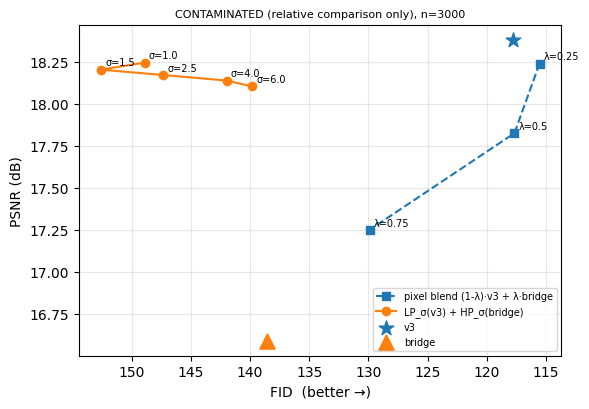

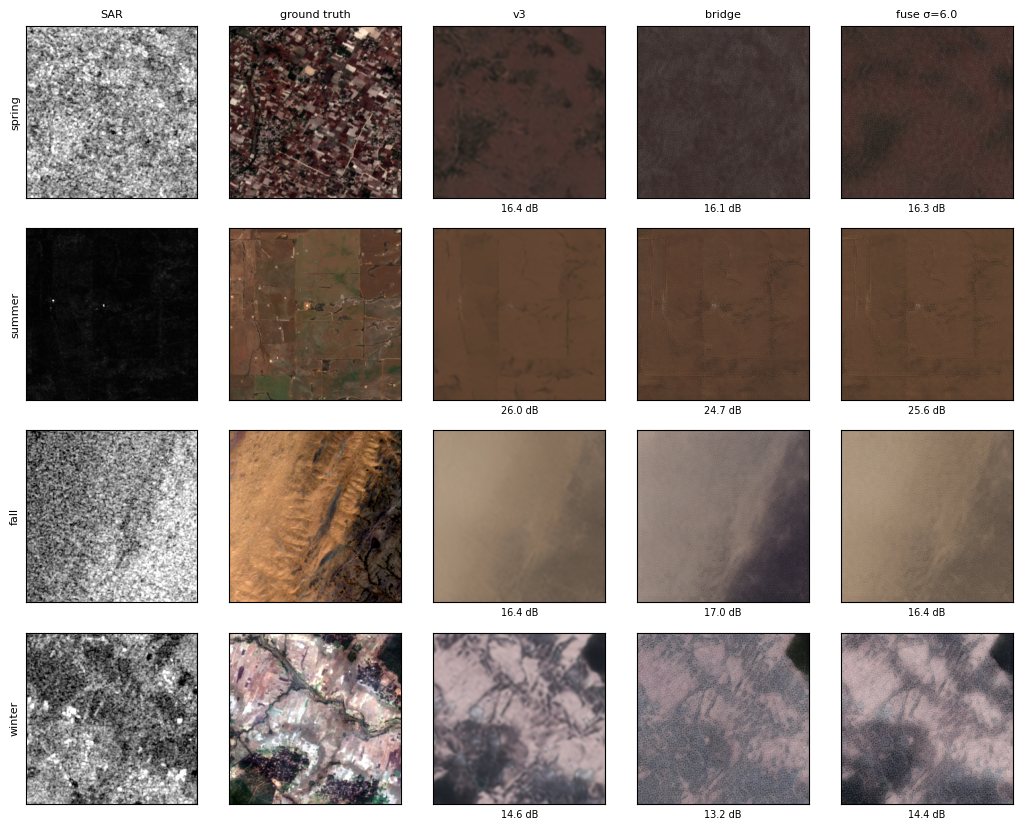

[13:29:13] done -> /kaggle/working/freq_split


In [10]:
# ---------------- step 4: PSNR-FID plane + sample grid ----------------
import matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(6, 4.2))
def pts(prefix): return RES[[i.startswith(prefix) for i in RES.index]]
for prefix, style, lab in (("blend", "s--", "pixel blend (1-λ)·v3 + λ·bridge"), ("fuse", "o-", "LP_σ(v3) + HP_σ(bridge)")):
    p = pts(prefix); ax.plot(p.FID, p.PSNR, style, label=lab)
    for i, r in p.iterrows(): ax.annotate(i.split()[-1], (r.FID, r.PSNR), fontsize=7, xytext=(3, 3), textcoords="offset points")
for n, mk in (("v3", "*"), ("bridge", "^")):
    ax.scatter(RES.loc[n].FID, RES.loc[n].PSNR, marker=mk, s=120, zorder=5, label=n)
ax.invert_xaxis(); ax.set_xlabel("FID  (better →)"); ax.set_ylabel("PSNR (dB)"); ax.grid(alpha=.3); ax.legend(fontsize=7)
ax.set_title(f"{TAG}, n={len(EVAL)}", fontsize=8); fig.tight_layout(); fig.savefig(f"{OUT}/psnr_fid.png", dpi=200); plt.show()

best = min(SIGMAS, key=lambda s: RES.loc[f"fuse σ={s}"].FID - 10 * RES.loc[f"fuse σ={s}"].dPSNR_vs_v3)
picks = [p for s in SEASONS for p in random.Random(5).sample([q for q in EVAL if q["season"] == s], 1)]
cols = ["SAR", "ground truth", "v3", "bridge", f"fuse σ={best}"]
fig, axs = plt.subplots(len(picks), len(cols), figsize=(2.1 * len(cols), 2.1 * len(picks)))
g = torch.Generator(device=dev).manual_seed(123)
with torch.no_grad():
    for r, p in enumerate(picks):
        d = PairDS([p])[0]; sar, gt = d["sar"][None].to(dev), d["opt"][None].to(dev); c = cond([p["season"]], [p["terrain"]]).to(dev)
        a, z = pred_v3(sar, c), pred_bridge(sar, c, g)
        for k, im in enumerate([sar, gt, a, z, fuse(a, z, best)]):
            axs[r, k].imshow(((im[0].clamp(-1, 1) + 1) / 2).permute(1, 2, 0).cpu().numpy()); axs[r, k].set_xticks([]); axs[r, k].set_yticks([])
            if k >= 2: axs[r, k].set_xlabel(f"{float(psnr_batch(im, gt)):.1f} dB", fontsize=7)
        axs[r, 0].set_ylabel(p["season"], fontsize=8)
for k, t in enumerate(cols): axs[0, k].set_title(t, fontsize=8)
fig.tight_layout(); fig.savefig(f"{OUT}/grid.png", dpi=160); plt.show()
log(f"done -> {OUT}")

**Reading the result.** With `PROTOCOL="relative"` only the *ordering* of variants is meaningful (does fusion beat blending at equal PSNR or equal FID); do not quote the absolute numbers as results. Fusion helps if some `fuse σ` point lies up-and-left of the blend curve (higher PSNR at equal FID, or
lower FID at equal PSNR). `dPSNR_vs_v3 ± se` is paired on identical images. FID with a few thousand images is biased and
seed-dependent: compare variants only within this run, and for the paper use `N_EVAL=None` plus 2–3 `BRIDGE_SEED`s.